Loading the dataset

In [1]:
import pandas as pd
import numpy as np

microdata_filepath = r"G:\My Drive\CIND820 - Capstone Project\Chs2022ecl_pumf.csv"
bootstrap_filepath = r"G:\My Drive\CIND820 - Capstone Project\Chs2022ecl_pumf_bsw.csv"

In [2]:
# Inspecting the data structure for microdata

df = pd.read_csv(microdata_filepath)

print("Number of rows and columns:", df.shape)
print("Unique IDs:", df["PUMFID"].nunique())
print("Missing IDs:", df["PUMFID"].isna().sum())
print("Duplicate IDs:", df["PUMFID"].duplicated().sum())
print("Columns:", df.columns.tolist())

Number of rows and columns: (38657, 103)
Unique IDs: 38657
Missing IDs: 0
Duplicate IDs: 0
Columns: ['PUMFID', 'EHA_10', 'EHA_25', 'FP_05', 'DWI_05A', 'DWI_05B', 'DWI_05C', 'DWI_05D', 'NEI_05A', 'NEI_05B', 'NEI_05C', 'NEI_05D', 'NEI_05E', 'NEI_05F', 'NEI_05G', 'NEI_05H', 'NEI_05I', 'WSA_05', 'SDH_05', 'CER_05', 'CER_20', 'LIS_10', 'COS_10', 'COS_15', 'GH_05', 'GH_10', 'REGION', 'PMINOR', 'PAGEP1', 'PCER_10', 'PCER_15', 'PCHN', 'PCOS_05', 'PDCT_05', 'P1DCT_20', 'P1DCT_25', 'PDV_SAH', 'PDV_SHCO', 'PDV_SUIT', 'PDWLTYPE', 'PDWS_05', 'PDWS_10A', 'PDWS_10B', 'PDWS_10C', 'PDWS_10D', 'PDWS_10E', 'PDWS_10F', 'PDWS_10G', 'PDWS_10H', 'PDWS_10I', 'PDWS_10J', 'PEHA_05A', 'PEHA_05B', 'PEHA_05C', 'PEMPL', 'PFTHB5YR', 'PFWEIGHT', 'PHGEDUC', 'PHHSIZE', 'PHHTTINC', 'PHTYPE', 'PLIS_05', 'PNES_05', 'PNSC_15', 'POWN_20', 'POWN_80', 'PPAC_05', 'PPAC_10', 'PPAC_23', 'PPAC_30', 'PPAC_35', 'PPAC_45A', 'PPAC_45C', 'PPAC_45D', 'PPAC_45E', 'PPAC_45F', 'PPAC_45G', 'PPAC_45H', 'PPAC_45I', 'PPAC_45J', 'PPAC_45K', 'P

In [44]:
# Inspecting the data structure for the bootstrap file

bsw_columns = pd.read_csv(bootstrap_filepath, nrows=0).columns
bsw_ids = pd.read_csv(bootstrap_filepath, usecols=["PUMFID"])

# as the data is large, I will only show the first 5 and last 3 headers.
print(len(bsw_columns), bsw_columns[:5].tolist(), bsw_columns[-3:].tolist())

# to check that both files have the same IDs
print("Same household IDs:", set(df.PUMFID) == set(bsw_ids.PUMFID))

# to check duplicates in the IDs
print("Duplicate bootstrap IDs:", bsw_ids["PUMFID"].duplicated().sum())



1001 ['PUMFID', 'BSW1', 'BSW2', 'BSW3', 'BSW4'] ['BSW998', 'BSW999', 'BSW1000']
Same household IDs: True
Duplicate bootstrap IDs: 0


In [4]:
# Applying binary classification

# count and sort the affordability-satisfaction column
print(df["PDWS_10C"].value_counts(dropna=False).sort_index())

# assign 0 as 'other stated reponse' and 1 as 'dissatisfied'
df["dissatisfied"] = df["PDWS_10C"].map({1:0,2:0, 3:0, 4:1})

analysis = df[df["dissatisfied"].notna()].copy()
print("Valid target records:", len(analysis))
print("Dissatisfied records:", int(analysis["dissatisfied"].sum()))

PDWS_10C
1    10645
2    16550
3     6649
4     4505
9      308
Name: count, dtype: int64
Valid target records: 38349
Dissatisfied records: 4505


### DATA PROFILING & AUDIT (EDA)

In [5]:
# Calculating the main weighted percentage

raw_pct = 100 * analysis["dissatisfied"].mean()
weighted_pct = 100 * np.average(
    analysis["dissatisfied"], weights=analysis["PFWEIGHT"]
)

print(f"Unweighted: {raw_pct:.1f}%")
print(f"Weighed: {weighted_pct:.1f}%")

Unweighted: 11.7%
Weighed: 14.6%


In [6]:
# checking there are no missing values in both variables
analysis[["dissatisfied", "PFWEIGHT"]].isna().sum()

dissatisfied    0
PFWEIGHT        0
dtype: int64

In [ ]:
# Reserved 'not stated' value codes

reserved = {
    "PDWS_10C": 9,
    "PDCT_05":9,
    "PHHTTINC": 99999999999,
    "PHHSIZE": 99,
    "PDWLTYPE": 99,
    "PDV_SHCO": 9999999.99,
}


for variable, code in reserved.items():
    count = int((df[variable] == code).sum())
    print(f"{variable}: {count:,} reserved values ({100*count/len(df):.1f}%)")

PDWS_10C: 308 reserved values (0.8%)
PDCT_05: 539 reserved values (1.4%)
PHHTTINC: 2,026 reserved values (5.2%)
PHHSIZE: 1,568 reserved values (4.1%)
PDWLTYPE: 1,605 reserved values (4.2%)
PDV_SHCO: 2,704 reserved values (7.0%)


In [8]:
# Creating a dictionary containing the reserved codes for each selected feature

# reserved codes for each variable
reserved_codes = {
    "PDWS_10C": 9,
        "PDCT_05":9,
        "PHHTTINC": 99999999999,
        "PHHSIZE": 99,
        "PDWLTYPE": 99,
        "PDV_SHCO": 9999999.99,
}

# replacing reserved codes with NaN and checking all have been replaced
for col, codes in reserved_codes.items():

    # convert a single code into a list
    if not isinstance(codes, (list, tuple, set)):
        codes = [codes]

    print(f"{col}:")
    print("Remaining reserved values:",
          analysis[col].isin(codes).sum())
    print("Missing values:", 
          analysis[col].isna().sum())
    print()
    



PDWS_10C:
Remaining reserved values: 0
Missing values: 0

PDCT_05:
Remaining reserved values: 536
Missing values: 0

PHHTTINC:
Remaining reserved values: 2016
Missing values: 0

PHHSIZE:
Remaining reserved values: 1558
Missing values: 0

PDWLTYPE:
Remaining reserved values: 1593
Missing values: 0

PDV_SHCO:
Remaining reserved values: 2690
Missing values: 0



In [9]:
# Percentage of Affordability dissatisfaction by Dwelling Ownership
ownership_labels = {1: "Onwer by member", 2: "Not owned by member"}
analysis["ownership"] = analysis["PDCT_05"].map(ownership_labels)

def weighted_rate(group):
    return 100 * np.average(group["dissatisfied"], weights=group["PFWEIGHT"])

for name, group in analysis.dropna(subset=["ownership"]).groupby("ownership"):
    print(name, "n=", len(group),"weighted rate =", f"{weighted_rate(group):.1f}%")



Not owned by member n= 21546 weighted rate = 20.8%
Onwer by member n= 16267 weighted rate = 11.3%


In [10]:
# Percentage of Affordability dissatisfaction by Province
province_labels = {
    10: "Newfoundland and Labrador",
    11: "Prince Edward Island",
    12: "Nova Scotia",
    13: "New Brunswick",
    24: "Quebec",
    35: "Ontario",
    46: "Manitoba",
    47: "Saskatchewan",
    48: "Alberta",
    59: "British Columbia",
}

analysis["province"] = analysis["PPROV"].map(province_labels)

for name, group in analysis.dropna(subset=["province"]).groupby("province"):
    print(name, "n=", len(group), "weighted rate=", f"{weighted_rate(group):.1f}%")

Alberta n= 4757 weighted rate= 15.3%
British Columbia n= 3836 weighted rate= 21.8%
Manitoba n= 2612 weighted rate= 10.2%
New Brunswick n= 3198 weighted rate= 9.2%
Newfoundland and Labrador n= 2812 weighted rate= 7.1%
Nova Scotia n= 3032 weighted rate= 11.0%
Ontario n= 7311 weighted rate= 16.7%
Prince Edward Island n= 1682 weighted rate= 8.3%
Quebec n= 5256 weighted rate= 9.2%
Saskatchewan n= 3853 weighted rate= 11.3%


In [11]:
# Percentage of Affordability dissatisfaction by Household size
household_size_labels = {
    1: "1 person",
    2: "2 people",
    3: "3 people",
    4: "4 people",
    5: "5 or more people",
}
analysis["household_size"] = analysis["PHHSIZE"].map(household_size_labels)

for name, group in analysis.dropna(subset=["household_size"]).groupby("household_size"):
    print(name, "n=", len(group), "weighted rate =", f"{weighted_rate(group):.1f}%")

1 person n= 16700 weighted rate = 14.6%
2 people n= 11894 weighted rate = 12.8%
3 people n= 3727 weighted rate = 15.2%
4 people n= 2885 weighted rate = 15.5%
5 or more people n= 1585 weighted rate = 16.6%


In [12]:
# Percentage of Affordability dissatisfacion by Annual household income groups
income = analysis["PHHTTINC"].replace(99999999999, np.nan)

analysis["income_group"] = pd.cut(
    income,
    bins=[-np.inf, 50000, 100000, 150000, np.inf],
    labels=["Up to $50k", "$50k-$100k", "$100k-$150k", "Over $150k"],
)

for name, group in analysis.dropna(subset=["income_group"]).groupby(
    "income_group", observed=True
):
    print(name, "n=", len(group), "weighted rate =", f"{weighted_rate(group):.1f}%")

Up to $50k n= 15632 weighted rate = 13.9%
$50k-$100k n= 10547 weighted rate = 15.4%
$100k-$150k n= 5219 weighted rate = 15.2%
Over $150k n= 4935 weighted rate = 13.7%


In [ ]:
# Checking missing values
candidate_features = [
    "PPROV",
    "PDCT_05",
    "PHHSIZE",
    "PHHTTINC",
    "PDWLTYPE",
    "PDV_SHCO"
]

# Creating a copy to avoid modifying the original data
feature_audit = analysis[candidate_features].copy()


# Summarizing data quality
audit_summary = pd.DataFrame({
    "Missing Count" : feature_audit.isna().sum(),
    "Missing %" : feature_audit.isna().mean() * 100,
    "Unique Values" : feature_audit.nunique()
})

# displaying results
print(audit_summary.round(2))

          Missing Count  Missing %  Unique Values
PPROV                 0        0.0             10
PDCT_05               0        0.0              3
PHHSIZE               0        0.0              6
PHHTTINC              0        0.0            211
PDWLTYPE              0        0.0              7
PDV_SHCO              0        0.0             63


In [14]:
# checking all the reserved codes were used
for col, code in reserved_codes.items():
    print(col, ":", (analysis[col] == code).sum())

PDWS_10C : 0
PDCT_05 : 536
PHHTTINC : 2016
PHHSIZE : 1558
PDWLTYPE : 1593
PDV_SHCO : 2690


In [15]:
categorical_features = [
    "PPROV",
    "PDCT_05",
    "PHHSIZE",
    "PDWLTYPE"
]

for col in categorical_features:
    
    temp = analysis[[col, "dissatisfied", "PFWEIGHT"]].copy()

    # remove observations with missing values
    temp = temp.dropna(subset=[col, "dissatisfied", "PFWEIGHT"])

    # calculate weighted dissatisfaction rate
    rates = (
        temp.groupby(col)
        .apply(weighted_rate, include_groups=False)
    )

    print(f"\n{col}")
    print(rates.round(2))


PPROV
PPROV
10     7.07
11     8.34
12    11.04
13     9.16
24     9.16
35    16.72
46    10.16
47    11.30
48    15.30
59    21.82
dtype: float64

PDCT_05
PDCT_05
1    11.28
2    20.75
9    12.24
dtype: float64

PHHSIZE
PHHSIZE
1     14.63
2     12.81
3     15.24
4     15.50
5     16.64
99    21.78
dtype: float64

PDWLTYPE
PDWLTYPE
1     10.71
2      8.35
3     15.63
4     15.09
5     26.70
6     18.95
99    10.59
dtype: float64


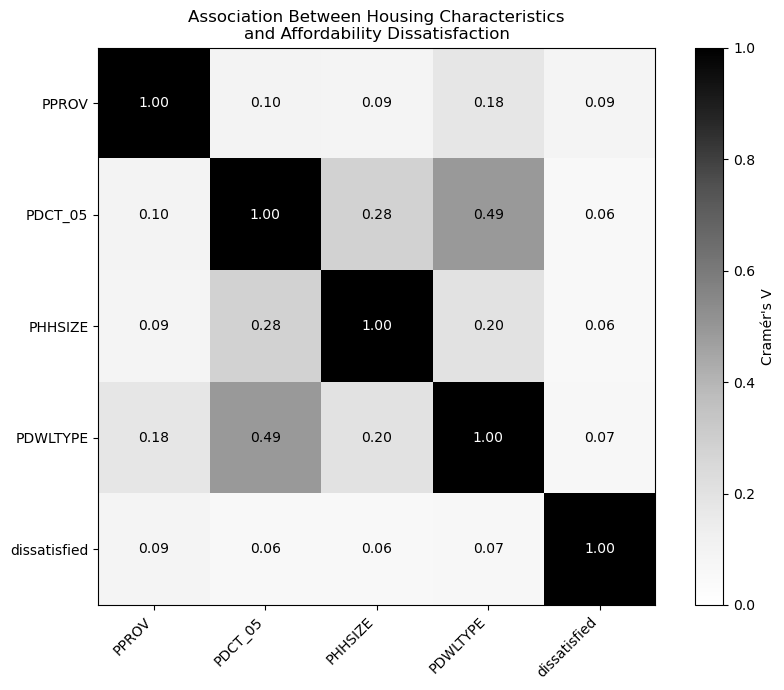

In [16]:
# Creating a Cramer's V heatmap

import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency

# Cramer's V function
def creamers_v(x, y):
    
    valid = pd.DataFrame({
        "x":x,
        "y":y
    }).dropna()

    table = pd.crosstab(valid["x"], valid["y"])

    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(
        table,
        correction=False
    )[0]

    n = table.to_numpy().sum()

    return np.sqrt(
        (chi2 / n) /
        min(table.shape[0] - 1, table.shape[1] - 1)
    )

# Prepare categorical variables
heatmap_data = feature_audit[
    ["PPROV", "PDCT_05", "PHHSIZE", "PDWLTYPE"]
].copy()

# Add target variable
heatmap_data["dissatisfied"] = analysis["dissatisfied"]

# calculate association matrix
columns = heatmap_data.columns

association_matrix = pd.DataFrame(
    index=columns,
    columns=columns,
    dtype=float
)

for col1 in columns:
    for col2 in columns:
        association_matrix.loc[col1, col2] = creamers_v(
            heatmap_data[col1],
            heatmap_data[col2]
        )

# plot heatmap
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    association_matrix,
    cmap="Greys",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(columns)))
ax.set_yticks(range(len(columns)))

ax.set_xticklabels(columns, rotation=45, ha="right")
ax.set_yticklabels(columns)

for i in range(len(columns)):
    for j in range(len(columns)):

        value = association_matrix.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > 0.5 else "black"
        )

fig.colorbar(im, ax=ax, label="Cramér's V")

ax.set_title(
    "Association Between Housing Characteristics\n"
    "and Affordability Dissatisfaction"
)

plt.tight_layout()
plt.show()


In [49]:
# Cross-tabulation for relationship between Ownership and Dwelling type
ownership_dwellingType = pd.crosstab(
    feature_audit["PDCT_05"],
    feature_audit["PDWLTYPE"],
    normalize="columns"
) * 100



display(ownership_dwellingType.round(1))


PDWLTYPE,1,2,3,4,5,6,99
PDCT_05,,,,,,,
1,84.4,49.3,26.0,46.2,8.9,10.7,40.1
2,14.5,49.2,72.8,52.6,90.7,88.5,48.9
9,1.2,1.6,1.1,1.3,0.4,0.8,11.0


<h5>Finding: 84.4% of single-detached house are owner-occupied and 90.7% apartments in buildings with more that five storeys are not owner-occupied. This suggests a strong descriptive association between dwelling type and homeownership status.</h5>

In [52]:
# Cross-tabulation for relationship between Dwelling type and target variable

dwellingType_targedVariable = pd.crosstab(
    feature_audit["PDCT_05"],
    analysis["dissatisfied"],
    normalize="columns"
) * 100

display(dwellingType_targedVariable.round(1))

dissatisfied,0.0,1.0
PDCT_05,,
1,43.4,34.8
2,55.2,64.0
9,1.4,1.3


<h5>Finding: 34.8% of dissatisfaction comes from owner-occupied houses and 64% comes from not owner-occupied. This indicates that non-owner-occupied households account for a larger proportion of dissatisfied households in the sample.</h5>

In [18]:
# making sure the reserved/missing codes are excluded before running the correlation

numeric_features = ["PHHTTINC", "PDV_SHCO"]

for col in numeric_features:
    print(f"\n{col}")
    print(analysis[col].value_counts().sort_index().tail(15))


PHHTTINC
PHHTTINC
500000            8
525000           39
550000           25
575000           27
600000            4
625000            4
650000           14
675000           20
700000           10
875000            2
900000           14
925000           23
950000           19
975000            3
99999999999    2016
Name: count, dtype: int64

PDV_SHCO
PDV_SHCO
4800.00         22
4900.00          6
5000.00         12
5100.00          9
5200.00          5
5300.00          7
5400.00         44
5500.00          1
5700.00          4
5800.00          1
7300.00         22
7400.00         14
7800.00         29
7900.00          7
9999999.99    2690
Name: count, dtype: int64


In [55]:
feature_audit = analysis[
    ["PPROV", "PDCT_05", "PHHSIZE",
     "PHHTTINC", "PDWLTYPE", "PDV_SHCO"]
].copy()

feature_audit["PHHTTINC"] = feature_audit["PHHTTINC"].replace(
    99999999999, np.nan
)

feature_audit["PDV_SHCO"] = feature_audit["PDV_SHCO"].replace(
    9999999.99, np.nan
)

print(feature_audit[["PHHTTINC", "PDV_SHCO"]].isna().sum())

PHHTTINC    2016
PDV_SHCO    2690
dtype: int64


<h5>The point-biseral correlation coefficient measures the strength and direction of the association between one continuous variable and one naturally or artificially dichotomous.</h5>

In [56]:
# Using point-biserial correlation because variable income is numerical but Dissatisfied is binary 

from scipy.stats import pointbiserialr

numeric_features = ["PHHTTINC", "PDV_SHCO"]

for col in numeric_features:

    temp = pd.DataFrame({
        "feature": feature_audit[col],
        "dissatisfied": analysis["dissatisfied"]
    }).dropna()

    r, p = pointbiserialr(
        temp["dissatisfied"],
        temp["feature"]
    )

    print(f"{col}")
    print(f"Correlation: {r:.4f}")
    print(f"P-value: {p:.4g}")
    print(f"Observations: {len(temp):,}")
    print()

PHHTTINC
Correlation: 0.0129
P-value: 0.01428
Observations: 36,333

PDV_SHCO
Correlation: 0.1834
P-value: 3.14e-267
Observations: 35,659



In [20]:
print(analysis["dissatisfied"])

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
38652    0.0
38653    1.0
38654    0.0
38655    0.0
38656    0.0
Name: dissatisfied, Length: 38349, dtype: float64


In [23]:
features_selected = [
    "PPROV",
    "PDCT_05",
    "PHHSIZE",
    "PHHTTINC",
    "PDWLTYPE",
    "PDV_SHCO"
]

analysis[features_selected].dtypes

PPROV         int64
PDCT_05       int64
PHHSIZE       int64
PHHTTINC      int64
PDWLTYPE      int64
PDV_SHCO    float64
dtype: object

### DATA PREPROCESSING

<h5>1. Indentifying predictors and target</h5>

In [26]:
# Nonimal categorical predictors
categorical_features = [
    "PPROV",
    "PDWLTYPE"
]

# Binary categorical predictor
binary_features = [
    "PDCT_05"
]

# Numerical predictors
numeric_features = [
    "PHHSIZE",
    "PHHTTINC",
    "PDV_SHCO"
]

In [27]:
# Checking missing values in selected predictors
selected_predictors = (
    categorical_features
    + binary_features
    +numeric_features
)

audit = analysis[selected_predictors].agg(
    ["count", "unique"]
).T

audit["Missing"] = analysis[selected_predictors].isna().sum()

audit["Missing%"] = (
    audit["Missing"] / len(analysis) * 100
).round(2)

audit

,count,unique,Missing,Missing%
PPROV,38349,"[11, 59, 47, 48, 35, 24, 46, 12, 10, 13]",0,0.0
PDWLTYPE,38349,"[2, 1, 4, 3, 5, 6, 99]",0,0.0
PDCT_05,38349,"[2, 1, 9]",0,0.0
PHHSIZE,38349,"[2, 99, 1, 3, 5, 4]",0,0.0
PHHTTINC,38349,"[82500, 95000, 50000, 170000, 57500, 87500, 12...",0,0.0
PDV_SHCO,38349,"[1100.0, 500.0, 600.0, 400.0, 800.0, 1200.0, 2...",0,0.0


In [28]:
# Handling the Ownership variable (binary)

analysis["PDCT_05_binary"] = analysis["PDCT_05"].map({
    1:1,
    2:0
})

In [29]:
# Replace reserved codes with NaN and verify
for col, codes in reserved_codes.items():

    # Convert a single code into a list
    if not isinstance(codes, (list, tuple, set)):
        codes = [codes]

    # REPLACE reserved codes with NaN
    analysis[col] = analysis[col].replace(codes, np.nan)

    # Verify replacement
    print(f"{col}:")
    print("Remaining reserved values:",
          analysis[col].isin(codes).sum())
    print("Missing values:",
          analysis[col].isna().sum())
    print()

PDWS_10C:
Remaining reserved values: 0
Missing values: 0

PDCT_05:
Remaining reserved values: 0
Missing values: 536

PHHTTINC:
Remaining reserved values: 0
Missing values: 2016

PHHSIZE:
Remaining reserved values: 0
Missing values: 1558

PDWLTYPE:
Remaining reserved values: 0
Missing values: 1593

PDV_SHCO:
Remaining reserved values: 0
Missing values: 2690



<H5>2. Splitting training and testing datasets</H5>

In [30]:
# Separating predictors (X) and target (y)

X = analysis[selected_predictors].copy()

# Replacing it with actual target column name
y = analysis["dissatisfied"]

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y #to maintain the class distribution in both datasets
)

In [ ]:
# Prepocessing pipelines

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Nominal categorical predictors
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),# mode
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Binary categorical predictor
binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),# mode
    ("encoder", OneHotEncoder(
        drop="if_binary",
        handle_unknown="ignore" # to avoid errors with unfamiliar categories
    ))
])

# Numerical predictors
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # average
    ("scaler", StandardScaler())
])

# Combining the three pipelines
preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("binary", binary_pipeline, binary_features),
    ("numeric", numeric_pipeline, numeric_features)
])

<h5>3. Applying the preprocessing</h5>

In [57]:
# Transformations from training data
X_train_processed = preprocessor.fit_transform(X_train) #learn the preprocessing rules and apply them

# Applying the same transformations to testing data
X_test_processed = preprocessor.transform(X_test) #applies existing rules

<h5>4. Verifying the transformation</h5>

In [58]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("n\Transformed features:")
print(preprocessor.get_feature_names_out())

Original training shape: (30679, 6)
Processed training shape: (30679, 20)
n\Transformed features:
['categorical__PPROV_10.0' 'categorical__PPROV_11.0'
 'categorical__PPROV_12.0' 'categorical__PPROV_13.0'
 'categorical__PPROV_24.0' 'categorical__PPROV_35.0'
 'categorical__PPROV_46.0' 'categorical__PPROV_47.0'
 'categorical__PPROV_48.0' 'categorical__PPROV_59.0'
 'categorical__PDWLTYPE_1.0' 'categorical__PDWLTYPE_2.0'
 'categorical__PDWLTYPE_3.0' 'categorical__PDWLTYPE_4.0'
 'categorical__PDWLTYPE_5.0' 'categorical__PDWLTYPE_6.0'
 'binary__PDCT_05_2.0' 'numeric__PHHSIZE' 'numeric__PHHTTINC'
 'numeric__PDV_SHCO']


<>:4: SyntaxWarning: invalid escape sequence '\T'
<>:4: SyntaxWarning: invalid escape sequence '\T'
C:\Users\danie\AppData\Local\Temp\ipykernel_12736\1596920193.py:4: SyntaxWarning: invalid escape sequence '\T'
  print("n\Transformed features:")


### TRAINING THE BASELINE MODEL

In [35]:
# DummyClassifier with strategy="prior"

from sklearn.dummy import DummyClassifier

# Creating the baseline model
dummy_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DummyClassifier(
        strategy="prior"
    ))
])

# Training the model
dummy_model.fit(X_train, y_train)

# Generating predictions
y_pred_dummy = dummy_model.predict(X_test)

# Generating probabilities for class 1
y_prob_dummy = dummy_model.predict_proba(X_test)[:, 1]

### EVALUATING THE DUMMY CLASSIFIER

DUMMY CLASSIFIER - BASELINE
----------------------------------------
                  precision    recall  f1-score   support

Not Dissatisfied       0.88      1.00      0.94      6769
    Dissatisfied       0.00      0.00      0.00       901

        accuracy                           0.88      7670
       macro avg       0.44      0.50      0.47      7670
    weighted avg       0.78      0.88      0.83      7670



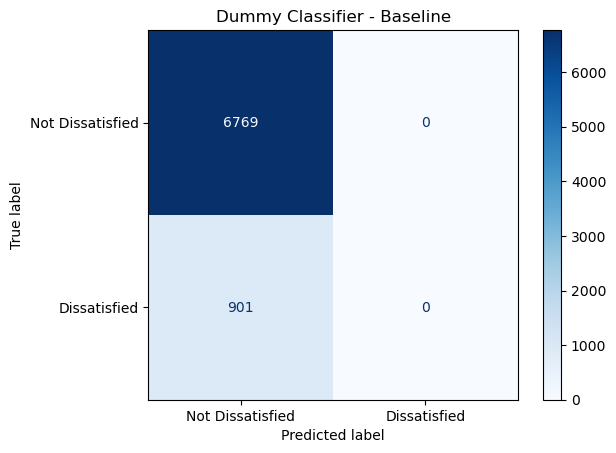

In [36]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Classification metrics
print("DUMMY CLASSIFIER - BASELINE")
print("-" * 40)

print(classification_report(
    y_test,
    y_pred_dummy,
    labels=[0, 1],
    target_names=["Not Dissatisfied", "Dissatisfied"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dummy,
    labels=[0, 1],
    display_labels=["Not Dissatisfied", "Dissatisfied"],
    cmap="Blues"
)

plt.title("Dummy Classifier - Baseline")
plt.show()



### TRAINING THE MODEL: LOGISTIC REGRESSION

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Logistic Regression model
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Training the model
logistic_model.fit(X_train, y_train)

# Predict actual classes (0 or 1)
y_pred_logistic = logistic_model.predict(X_test)

# Predict probability of dissatisfaction (class 1)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Evaluating the model
print("LOGISTIC REGRESSSION")
print("-" * 40)

print(classification_report(
    y_test,
    y_pred_logistic,
    labels=[0, 1],
    target_names=["Not Dissatisfied", "Dissatisfied"],
    zero_division=0
))

LOGISTIC REGRESSSION
----------------------------------------
                  precision    recall  f1-score   support

Not Dissatisfied       0.88      1.00      0.94      6769
    Dissatisfied       0.26      0.01      0.01       901

        accuracy                           0.88      7670
       macro avg       0.57      0.50      0.47      7670
    weighted avg       0.81      0.88      0.83      7670



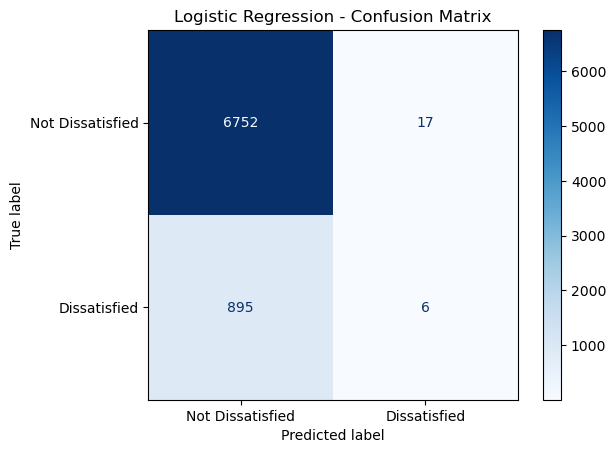

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    labels=[0, 1],
    display_labels=["Not Dissatisfied", "Dissatisfied"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### SECOND LOGISTIC REGRESSION WITH CLASS BALANCED

In [39]:
# Balanced Logistic Regression
logistic_balanced = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train
logistic_balanced.fit(X_train, y_train)

# Predict
y_pred_balanced = logistic_balanced.predict(X_test)

# Evaluate
print("BALANCED LOGISTIC REGRESSION")
print("-" * 40)

print(classification_report(
    y_test,
    y_pred_balanced,
    labels=[0, 1],
    target_names=["Not Dissatisfied", "Dissatisfied"],
    zero_division=0
))

BALANCED LOGISTIC REGRESSION
----------------------------------------
                  precision    recall  f1-score   support

Not Dissatisfied       0.94      0.66      0.77      6769
    Dissatisfied       0.20      0.66      0.31       901

        accuracy                           0.66      7670
       macro avg       0.57      0.66      0.54      7670
    weighted avg       0.85      0.66      0.72      7670



<h5>We can see an improvement on the recall from 1% from the normal logistic regression to 66% in the balanced logistic regression.</h5>

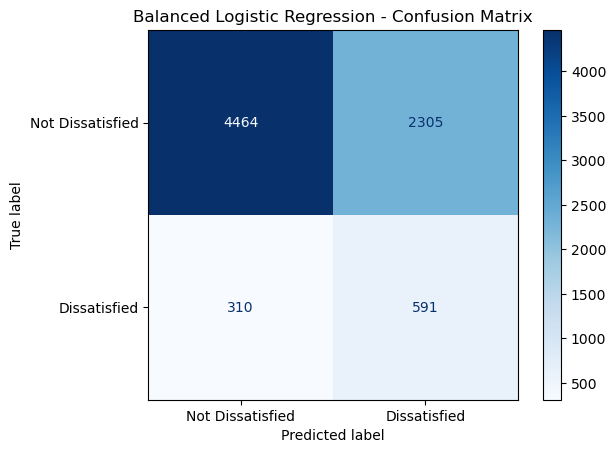

In [40]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced,
    labels=[0, 1],
    display_labels=["Not Dissatisfied", "Dissatisfied"],
    cmap="Blues"
)

plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.show()

### TRAINING THE MODEL: DECISION TREE CLASSIFIER

DECISION TREE CLASSIFIER
----------------------------------------
                  precision    recall  f1-score   support

Not Dissatisfied       0.89      0.90      0.90      6769
    Dissatisfied       0.21      0.20      0.21       901

        accuracy                           0.82      7670
       macro avg       0.55      0.55      0.55      7670
    weighted avg       0.81      0.82      0.82      7670



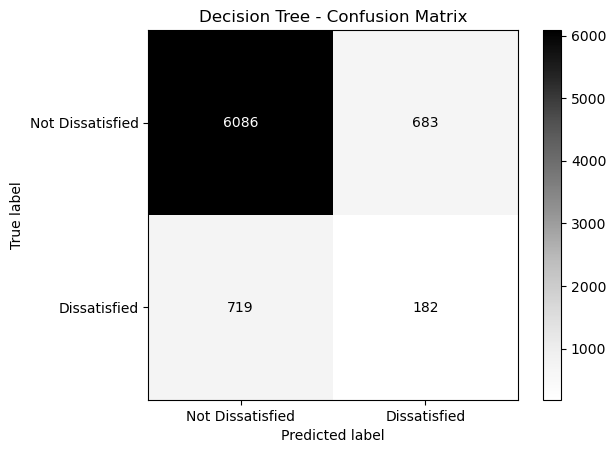

In [41]:
from sklearn.tree import DecisionTreeClassifier

# Decision Tree pipeline
decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# Training the model
decision_tree_model.fit(X_train, y_train)

# Predicting
y_pred_tree = decision_tree_model.predict(X_test)

# Classification report
print("DECISION TREE CLASSIFIER")
print("-" * 40)

print(classification_report(
    y_test,
    y_pred_tree,
    labels=[0, 1],
    target_names=["Not Dissatisfied", "Dissatisfied"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tree,
    labels=[0, 1],
    display_labels=["Not Dissatisfied", "Dissatisfied"],
    cmap="Greys"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

### TRAINING THE MODEL: RANDOM FOREST (UNBALANCED)

RANDOM FOREST CLASSFIER
----------------------------------------
                  precision    recall  f1-score   support

Not Dissatisfied       0.89      0.96      0.92      6769
    Dissatisfied       0.28      0.12      0.17       901

        accuracy                           0.86      7670
       macro avg       0.59      0.54      0.55      7670
    weighted avg       0.82      0.86      0.84      7670



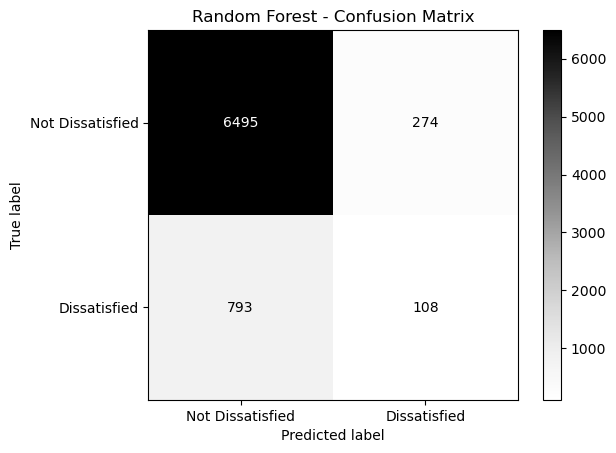

In [42]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest pipeline
random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Training the model
random_forest_model.fit(X_train, y_train)

# Predicting
y_pred_rf = random_forest_model.predict(X_test)

# Classification report
print('RANDOM FOREST CLASSFIER')
print("-" * 40)

print(classification_report(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    target_names=["Not Dissatisfied", "Dissatisfied"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    display_labels=["Not Dissatisfied", "Dissatisfied"],
    cmap="Greys"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

### TRAINING THE MODEL: SUPPORT VECTOR MACHINE

                  precision    recall  f1-score   support

Not Dissatisfied       0.88      1.00      0.94      6769
    Dissatisfied       0.00      0.00      0.00       901

        accuracy                           0.88      7670
       macro avg       0.44      0.50      0.47      7670
    weighted avg       0.78      0.88      0.83      7670



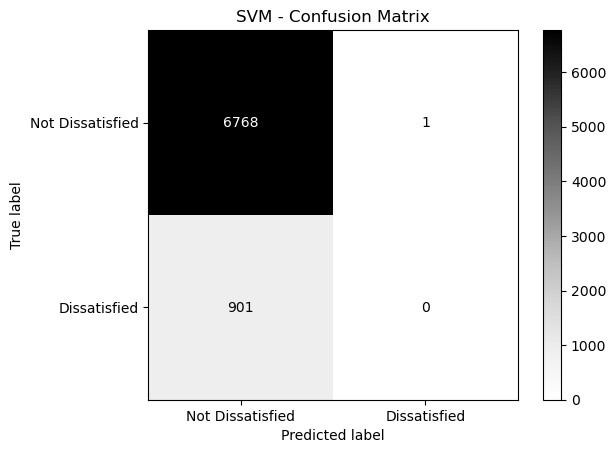

In [43]:
from sklearn.svm import SVC

# SVM classification model
svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    ))
])

# Training the model
svm_model.fit(X_train,y_train)

# Predicting
y_pred_svm = svm_model.predict(X_test)

# Classification report
print(classification_report(
    y_test,
    y_pred_svm,
    labels=[0, 1],
    target_names=["Not Dissatisfied", "Dissatisfied"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    labels=[0, 1],
    display_labels=["Not Dissatisfied", "Dissatisfied"],
    cmap="Greys"
)

plt.title("SVM - Confusion Matrix")
plt.show()